<a href="https://colab.research.google.com/github/niofrequency/google-collab_image/blob/main/BIGLUST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%cd /content
# --- Google Drive: keep downloaded LoRAs between Colab sessions (set to False to skip) ---
USE_GOOGLE_DRIVE = True
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")  # Colab asks you to allow access

!git clone https://github.com/comfyanonymous/ComfyUI /content/ComfyUI
!git clone https://github.com/city96/ComfyUI-GGUF /content/ComfyUI/custom_nodes/ComfyUI-GGUF
!pip install -q torchsde gguf
!pip install -q -r /content/ComfyUI/requirements.txt
!apt install aria2 -qqy

!mkdir -p /content/ComfyUI/models/checkpoints /content/ComfyUI/models/loras

# Store LoRAs in MyDrive/ComfyUI/loras_sdxl: ComfyUI's loras folder becomes a link to it, so LoRAs
# downloaded from the website are saved to Drive and show up again in every new session.
import os, shutil
LORA_LOCAL = "/content/ComfyUI/models/loras"
if USE_GOOGLE_DRIVE:
    DRIVE_LORAS = "/content/drive/MyDrive/ComfyUI/loras_sdxl"
    os.makedirs(DRIVE_LORAS, exist_ok=True)
    if not os.path.islink(LORA_LOCAL):
        if os.path.isdir(LORA_LOCAL):
            for f in os.listdir(LORA_LOCAL):  # keep anything already downloaded in this session
                src, dst = os.path.join(LORA_LOCAL, f), os.path.join(DRIVE_LORAS, f)
                if not f.startswith("put_") and not os.path.exists(dst):
                    shutil.move(src, dst)
            shutil.rmtree(LORA_LOCAL)
        os.symlink(DRIVE_LORAS, LORA_LOCAL)
    n = len([f for f in os.listdir(DRIVE_LORAS) if not f.endswith(".part")])
    print(f"LoRAs are stored in Google Drive (MyDrive/ComfyUI/loras_sdxl): {n} file(s)")
else:
    os.makedirs(LORA_LOCAL, exist_ok=True)
    print("LoRAs are stored on this runtime only (lost when the runtime is deleted)")

# Download BigLust (SDXL checkpoint)
!wget -q --show-progress -O /content/ComfyUI/models/checkpoints/biglust.safetensors \
  "https://civitai.com/api/download/models/1081768?fileId=986850&token=777a5632707c15ecf54e13eb3b1b862b"

# Download VAE (SDXL VAE is recommended for BigLust)
!mkdir -p /content/ComfyUI/models/vae
!aria2c --console-log-level=error -c -x 16 -s 16 -k 1M \
  https://huggingface.co/stabilityai/sdxl-vae/resolve/main/sdxl_vae.safetensors \
  -d /content/ComfyUI/models/vae -o sdxl_vae.safetensors


# Check downloads
!ls -lh /content/ComfyUI/models/checkpoints/
!ls -lh /content/ComfyUI/models/loras/
!ls -lh /content/ComfyUI/models/vae/

/content
Cloning into '/content/ComfyUI'...
remote: Enumerating objects: 65369, done.
remote: Counting objects: 100% (922/922), done.
remote: Compressing objects: 100% (306/306), done.
remote: Total 65369 (delta 785), reused 616 (delta 616), pack-reused 64447 (from 5)
Receiving objects: 100% (65369/65369), 106.82 MiB | 14.32 MiB/s, done.
Resolving deltas: 100% (45116/45116), done.
Cloning into '/content/ComfyUI/custom_nodes/ComfyUI-GGUF'...
remote: Enumerating objects: 814, done.
remote: Counting objects: 100% (570/570), done.
remote: Compressing objects: 100% (206/206), done.
remote: Total 814 (delta 515), reused 364 (delta 364), pack-reused 244 (from 1)
Receiving objects: 100% (814/814), 187.82 KiB | 1.49 MiB/s, done.
Resolving deltas: 100% (545/545), done.
The following additional packages will be installed:
  libaria2-0 libcares2
The following NEW packages will be installed:
  aria2 libaria2-0 libcares2
0 upgraded, 3 newly installed, 0 to remove and 33 not upgraded.
Need to get 1,5

In [2]:
%cd /content/ComfyUI

import torch
import random, time
from PIL import Image
import numpy as np
import logging
import warnings

# Hide warnings
logging.getLogger("root").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

from nodes import NODE_CLASS_MAPPINGS

CheckpointLoaderSimple = NODE_CLASS_MAPPINGS["CheckpointLoaderSimple"]()
CLIPTextEncode = NODE_CLASS_MAPPINGS["CLIPTextEncode"]()
VAELoader = NODE_CLASS_MAPPINGS["VAELoader"]()
KSampler = NODE_CLASS_MAPPINGS["KSampler"]()
VAEDecode = NODE_CLASS_MAPPINGS["VAEDecode"]()
EmptyLatentImage = NODE_CLASS_MAPPINGS["EmptyLatentImage"]()

with torch.inference_mode():
    # Load BigLust checkpoint
    ckpt = CheckpointLoaderSimple.load_checkpoint("biglust.safetensors")
    unet = ckpt[0]
    clip = ckpt[1]
    vae = ckpt[2]

print("BigLust loaded.")
print("Sampler will be dpmpp_2m + karras in Cell 3.")

/content/ComfyUI
BigLust loaded.
Sampler will be dpmpp_2m + karras in Cell 3.


/content/ComfyUI


  0%|          | 0/25 [00:00<?, ?it/s]

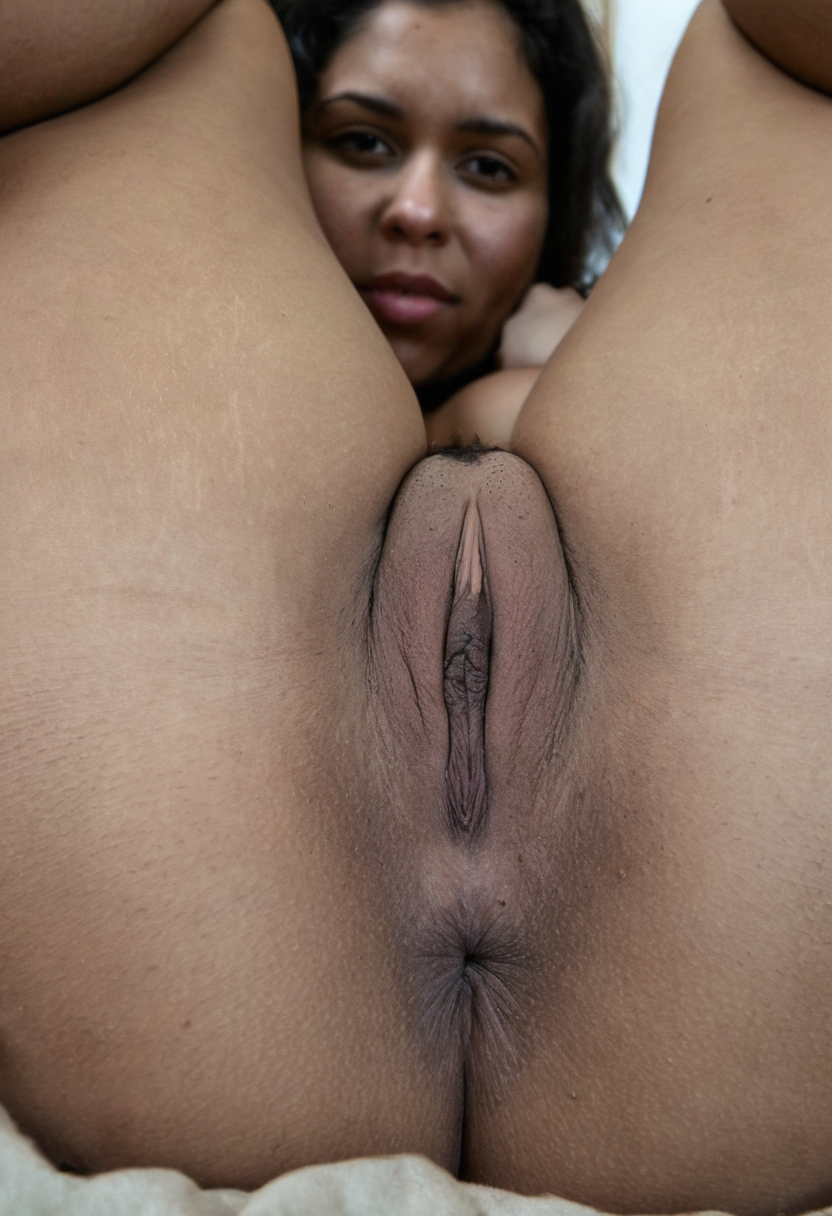

Saved to /content/test.png


In [ ]:
%cd /content/ComfyUI

import torch
import random, time
from PIL import Image
import numpy as np
from IPython.display import display
from nodes import NODE_CLASS_MAPPINGS
import logging
import warnings

# Hide the LoRA key warnings
logging.getLogger("root").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

CheckpointLoaderSimple = NODE_CLASS_MAPPINGS["CheckpointLoaderSimple"]()
LoraLoaderModelOnly = NODE_CLASS_MAPPINGS["LoraLoaderModelOnly"]()
CLIPTextEncode = NODE_CLASS_MAPPINGS["CLIPTextEncode"]()
EmptyLatentImage = NODE_CLASS_MAPPINGS["EmptyLatentImage"]()
KSampler = NODE_CLASS_MAPPINGS["KSampler"]()
VAEDecode = NODE_CLASS_MAPPINGS["VAEDecode"]()

with torch.inference_mode():
    # Load BigLust
    ckpt = CheckpointLoaderSimple.load_checkpoint("biglust.safetensors")
    unet = ckpt[0]
    clip = ckpt[1]
    vae = ckpt[2]

    seed = 0
    steps = 25
    cfg = 4.5
    sampler_name = "dpmpp_2m"
    scheduler = "karras"
    width = 832
    height = 1216

    positive_prompt = "Her full face and vagina in the shot, chubby latina woman holding her thick thighs, medium close-up, low-angle perspective from between the legs of a naked Latina woman. Highly detailed natural vulva, realistic labia majora and minora with natural folds, asymmetry and texture, visible clitoral hood, realistic pubic hair that is not perfectly trimmed, subtle natural moisture and skin sheen only on the genitals, visible pores, fine skin texture, slight natural imperfections, not smooth, not plastic. The woman is holding her legs up, spreading wide, looking down at the camera with a seductive expression. Shallow depth of field, raw photograph, highly detailed anatomy, photorealistic skin texture, 8k, natural lighting"
    negative_prompt = "plastic skin, glossy skin, oily skin, waxy skin, airbrushed, over-smoothed, excessive shine, artificial wetness, cgi, 3d render, doll-like, smooth skin, bright red labia, cartoon vulva, artificial anatomy, 色调艳丽，过曝，静态，细节模糊不清，字幕，风格，作品，画作，画面，静止，整体发灰，最差质量，低质量，JPEG压缩残留，丑陋的，残缺的，多余的手指，画得不好的手部，画得不好的脸部，畸形的，毁容的，形态畸形的肢体，手指融合，静止不动的画面，杂乱的背景，三条腿，背景人很多，倒着走"

    positive = CLIPTextEncode.encode(clip, positive_prompt)[0]
    negative = CLIPTextEncode.encode(clip, negative_prompt)[0]
    latent_image = EmptyLatentImage.generate(width, height)[0]

    if seed == 0:
        random.seed(int(time.time()))
        seed = random.randint(0, 18446744073709551615)

    # Fixed: Passing 'unet' instead of undefined 'lora'
    samples = KSampler.sample(unet, seed, steps, cfg, sampler_name, scheduler, positive, negative, latent_image)[0]
    decoded = VAEDecode.decode(vae, samples)[0].detach()

    img_array = (decoded.cpu().numpy() * 255).clip(0, 255).astype(np.uint8)[0]
    image = Image.fromarray(img_array)
    image.save("/content/test.png")
    display(image)

print("Saved to /content/test.png")

In [ ]:
# ========== BigLust / any SDXL API + Cloudflare Tunnel ==========
# Finishes after printing the URL; the server keeps running in the background. Re-running this cell
# updates the running server instead of starting a new one (safe: it no longer restarts the session).
# Add any SDXL (or SD1.5) checkpoint or LoRA from the website with "+ Add Checkpoint" / "+ Add LoRA":
# paste a Civitai page or download link, or a Hugging Face file link. Files are saved in
# /content/ComfyUI/models/{checkpoints,loras} and appear in the website's lists.
%cd /content/ComfyUI

!pip install -q fastapi uvicorn python-multipart requests
import os
if not os.path.exists("/tmp/cloudflared"):  # don't overwrite it while the tunnel is running
    !wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /tmp/cloudflared
    !chmod +x /tmp/cloudflared

import os
import re
import gc
import time
import uuid
import base64
import random
import threading
import subprocess
import traceback
import urllib.parse
from io import BytesIO
from typing import List, Optional

import numpy as np
import requests
import torch
from PIL import Image
from fastapi import FastAPI
from fastapi.middleware.cors import CORSMiddleware
from pydantic import BaseModel

import comfy.utils
import comfy.model_management
from nodes import NODE_CLASS_MAPPINGS

# Optional: your Civitai API key (some models need it). The website also sends one.
CIVITAI_TOKEN = os.environ.get("CIVITAI_TOKEN", "")

MODELS_DIR = "/content/ComfyUI/models"
CKPT_DIR = os.path.join(MODELS_DIR, "checkpoints")
LORA_DIR = os.path.join(MODELS_DIR, "loras")
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(LORA_DIR, exist_ok=True)
MODEL_EXTS = (".safetensors", ".ckpt", ".pt", ".pth", ".bin")
DEFAULT_CHECKPOINT = "biglust.safetensors"

CLIPTextEncode = NODE_CLASS_MAPPINGS["CLIPTextEncode"]()
EmptyLatentImage = NODE_CLASS_MAPPINGS["EmptyLatentImage"]()
KSampler = NODE_CLASS_MAPPINGS["KSampler"]()
VAEDecode = NODE_CLASS_MAPPINGS["VAEDecode"]()
CheckpointLoaderSimple = NODE_CLASS_MAPPINGS["CheckpointLoaderSimple"]()

app = FastAPI()
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

# ---------------- checkpoints: keep exactly one loaded ----------------
loaded = globals().get("loaded") if isinstance(globals().get("loaded"), dict) else {"name": None, "model": None, "clip": None, "vae": None}
if loaded["name"] is None and "unet" in globals() and "clip" in globals() and "vae" in globals():
    loaded.update(name=DEFAULT_CHECKPOINT, model=unet, clip=clip, vae=vae)  # loaded by cell 3


def list_files(folder):
    out = []
    for root, _, files in os.walk(folder):
        for f in files:
            if f.lower().endswith(MODEL_EXTS):
                out.append(os.path.relpath(os.path.join(root, f), folder))
    return sorted(out, key=str.lower)


def get_checkpoint(name):
    name = name or DEFAULT_CHECKPOINT
    if loaded["name"] == name:
        return loaded["model"], loaded["clip"], loaded["vae"]
    if name not in list_files(CKPT_DIR):
        raise ValueError(f"Checkpoint not found: {name}")
    print(f"Switching checkpoint: {loaded['name']} -> {name}")
    # free the previous checkpoint first so two SDXL models never sit in RAM together
    loaded.update(name=None, model=None, clip=None, vae=None)
    for g in ("unet", "clip", "vae"):
        globals().pop(g, None)
    comfy.model_management.unload_all_models()
    gc.collect()
    comfy.model_management.soft_empty_cache()
    with torch.inference_mode():
        m, c, v = CheckpointLoaderSimple.load_checkpoint(name)[:3]
    loaded.update(name=name, model=m, clip=c, vae=v)
    return m, c, v


# ---------------- downloads (background, streamed to disk) ----------------
JOBS = globals().get("JOBS") if isinstance(globals().get("JOBS"), dict) else {}  # kept across re-runs


def new_job(kind, **extra):
    job_id = uuid.uuid4().hex[:12]
    JOBS[job_id] = {"kind": kind, "status": "queued", "created": time.time(), "error": None, **extra}
    now = time.time()
    for jid in [j for j, v in JOBS.items() if v["status"] in ("done", "error") and now - v["created"] > 1800]:
        JOBS.pop(jid, None)
    return job_id


def resolve_url(url):
    """Turn page links into direct download links. Returns (download_url, suggested_name)."""
    url = url.strip()
    parsed = urllib.parse.urlparse(url)
    qs = urllib.parse.parse_qs(parsed.query)
    token = (qs.get("token") or [CIVITAI_TOKEN])[0]
    host = parsed.netloc.lower()

    if "civitai.com" in host or "civitai.red" in host:
        api_headers = {"Authorization": f"Bearer {token}"} if token else {}
        m = re.search(r"/api/download/models/(\d+)", parsed.path)
        if not m:
            version_id = (qs.get("modelVersionId") or [None])[0]
            if not version_id:
                mm = re.search(r"/models/(\d+)", parsed.path)
                if not mm:
                    raise ValueError("Unrecognised Civitai link. Use a model page or download link.")
                info = requests.get(f"https://civitai.com/api/v1/models/{mm.group(1)}", headers=api_headers, timeout=30)
                info.raise_for_status()
                versions = info.json().get("modelVersions") or []
                if not versions:
                    raise ValueError("That Civitai model has no downloadable versions.")
                version_id = versions[0]["id"]  # newest version
            url = f"https://civitai.com/api/download/models/{version_id}"
        else:
            url = f"https://civitai.com/api/download/models/{m.group(1)}"
        if token:
            url += "?token=" + urllib.parse.quote(token)
        return url, None

    if "huggingface.co" in host:
        url = url.replace("/blob/", "/resolve/")
        return url, os.path.basename(urllib.parse.urlparse(url).path)

    return url, os.path.basename(parsed.path)


def filename_from_response(resp, fallback):
    cd = resp.headers.get("content-disposition", "")
    m = re.search(r"filename\*=(?:UTF-8'')?([^;]+)", cd, re.I) or re.search(r'filename="?([^";]+)"?', cd, re.I)
    name = urllib.parse.unquote(m.group(1).strip()) if m else (fallback or "")
    name = os.path.basename(name).strip().strip('"')
    name = re.sub(r"[^\w.\-+() ]", "_", name)
    return name


def run_download(job_id, url, kind):
    job = JOBS[job_id]
    job["status"] = "running"
    folder = LORA_DIR if kind == "lora" else CKPT_DIR
    tmp_path = None
    try:
        dl_url, suggested = resolve_url(url)
        with requests.get(dl_url, stream=True, timeout=60, allow_redirects=True,
                          headers={"User-Agent": "Mozilla/5.0"}) as r:
            if r.status_code in (401, 403):
                raise ValueError("Access denied — this model needs a Civitai API key (set CIVITAI_TOKEN or add ?token=...)")
            r.raise_for_status()
            if "text/html" in r.headers.get("content-type", ""):
                raise ValueError("The link returned a web page, not a model file. Use the download link.")
            name = filename_from_response(r, suggested)
            if not name.lower().endswith(MODEL_EXTS):
                name = f"{kind}_{int(time.time())}.safetensors"
            job["filename"] = name
            path = os.path.join(folder, name)
            if os.path.exists(path):
                job["status"], job["progress"] = "done", 100
                return
            total = int(r.headers.get("content-length") or 0)
            job["total_mb"] = round(total / 1e6) if total else None
            tmp_path = path + ".part"
            done = 0
            with open(tmp_path, "wb") as f:
                for chunk in r.iter_content(chunk_size=8 * 1024 * 1024):
                    f.write(chunk)
                    done += len(chunk)
                    job["done_mb"] = round(done / 1e6)
                    job["progress"] = round(done * 100 / total) if total else None
            os.replace(tmp_path, path)
            tmp_path = None
        job["status"], job["progress"] = "done", 100
        print(f"Downloaded {kind}: {name} ({job.get('done_mb')} MB)")
    except Exception as e:
        traceback.print_exc()
        job["status"], job["error"] = "error", str(e)
    finally:
        if tmp_path and os.path.exists(tmp_path):
            os.remove(tmp_path)


class ModelDownload(BaseModel):
    url: str
    type: str = "checkpoint"


@app.post("/download_model")
def download_model(req: ModelDownload):
    kind = "lora" if req.type == "lora" else "checkpoint"
    job_id = new_job("download", type=kind, filename=None, progress=0, done_mb=0, total_mb=None)
    threading.Thread(target=run_download, args=(job_id, req.url, kind), daemon=True).start()
    return {"job_id": job_id, "status": "queued", "type": kind}


@app.get("/user_models")
def get_user_models():
    ckpts = list_files(CKPT_DIR)
    if DEFAULT_CHECKPOINT in ckpts:  # default first
        ckpts.remove(DEFAULT_CHECKPOINT)
        ckpts.insert(0, DEFAULT_CHECKPOINT)
    return {
        "checkpoints": ckpts,
        "lora_files": list_files(LORA_DIR),
        "model_type": "sdxl",
        "default_checkpoint": DEFAULT_CHECKPOINT,
        "samplers": ["dpmpp_2m", "dpmpp_2m_sde", "dpmpp_sde", "euler", "euler_ancestral", "dpmpp_3m_sde", "uni_pc"],
        "schedulers": ["karras", "normal", "simple", "exponential", "sgm_uniform"],
    }


# ---------------- LoRA loading with a compatibility check ----------------
# ComfyUI silently skips LoRA layers that don't exist in the model, so a LoRA made for another
# model (e.g. SDXL on Qwen) would quietly do nothing. Count what matches and say so.
import comfy.lora
import comfy.lora_convert
import comfy.sd
import folder_paths

_LORA_SUFFIXES = (".lora_up.weight", ".lora_down.weight", ".lora_A.weight", ".lora_B.weight",
                  ".lora_mid.weight", ".lora.up.weight", ".lora.down.weight", ".diff", ".hada_w1_a",
                  ".lokr_w1", ".lokr_w1_a", ".oft_blocks", ".w_norm", ".set_weight")


def apply_lora_checked(model, clip, name, strength_model, strength_clip, model_label):
    """Apply a LoRA like ComfyUI's LoraLoader. Returns (model, clip, warning_or_None).
    Raises ValueError if none of the LoRA's layers match the model."""
    path = folder_paths.get_full_path_or_raise("loras", name)
    lora, metadata = comfy.utils.load_torch_file(path, safe_load=True, return_metadata=True)
    key_map = {}
    if model is not None:
        key_map = comfy.lora.model_lora_keys_unet(model.model, key_map)
    if clip is not None:
        key_map = comfy.lora.model_lora_keys_clip(clip.cond_stage_model, key_map)
    converted = comfy.lora_convert.convert_lora(dict(lora))
    patches = comfy.lora.load_lora(converted, key_map, log_missing=False)
    matched = sum(1 for k in patches if not (isinstance(k, str) and k.endswith(".config")))
    layers = {k[: -len(s)] for k in converted for s in _LORA_SUFFIXES if k.endswith(s)}
    total = len(layers)
    if matched == 0:
        raise ValueError(
            f"LoRA '{name}' doesn't match the {model_label} model (0 of {total or '?'} layers matched). "
            f"It was probably made for a different model — remove it or pick a {model_label} LoRA.")
    warning = None
    if total and matched < 0.5 * total:
        warning = (f"LoRA '{name}': only {matched} of {total} layers matched the {model_label} model, "
                   f"so it may have little effect (probably made for a different model version).")
    print(f"  LoRA {name} @ {strength_model}: {matched}/{total or '?'} layers matched")
    new_model, new_clip = comfy.sd.load_lora_for_models(model, clip, lora, strength_model, strength_clip,
                                                        lora_metadata=metadata)
    return new_model, new_clip, warning


# ---------------- generation (background job, polled by the website) ----------------
class LoraItem(BaseModel):
    name: str
    strength: float = 1.0


class GenerateRequest(BaseModel):
    checkpoint: Optional[str] = None
    sampler: str = "dpmpp_2m"
    scheduler: str = "karras"
    steps: int = 25
    cfg: float = 4.5
    width: int = 832
    height: int = 1216
    batch_size: int = 1
    seed: int = -1
    loras: List[LoraItem] = []
    positive: str = ""
    negative: str = ""


gpu_lock = globals().get("gpu_lock") if isinstance(globals().get("gpu_lock"), type(threading.Lock())) else threading.Lock()
current_job = globals().get("current_job") if isinstance(globals().get("current_job"), dict) else {"id": None}


def progress_hook(value, total, *args, **kwargs):
    job = JOBS.get(current_job["id"])
    if job and total:
        job["step"], job["total_steps"] = int(value), int(total)


comfy.utils.set_progress_bar_global_hook(progress_hook)


def to_data_url(img_tensor):
    arr = (img_tensor.cpu().numpy() * 255).clip(0, 255).astype(np.uint8)
    buf = BytesIO()
    Image.fromarray(arr).save(buf, format="PNG")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()


def run_generate(job_id, req):
    job = JOBS[job_id]
    with gpu_lock:
        current_job["id"] = job_id
        job["status"] = "running"
        try:
            model, clip_m, vae_m = get_checkpoint(req.checkpoint)
            available_loras = set(list_files(LORA_DIR))
            batch = max(1, min(int(req.batch_size or 1), 8))
            w = max(256, min(int(req.width), 2048)) // 8 * 8
            h = max(256, min(int(req.height), 2048)) // 8 * 8
            seed = req.seed if req.seed and req.seed > 0 else random.randint(0, 2**63 - 1)
            print(f"[{job_id}] {loaded['name']}, {len(req.loras)} LoRA(s), {req.steps} steps, {w}x{h}, batch={batch}")
            warnings = []
            with torch.inference_mode():
                for l in req.loras:
                    if not l.name or l.strength == 0:
                        continue
                    if l.name not in available_loras:
                        raise ValueError(f"LoRA not found on the server: {l.name}")
                    model, clip_m, warning = apply_lora_checked(model, clip_m, l.name, float(l.strength),
                                                                float(l.strength), "SDXL")
                    if warning:
                        warnings.append(warning)
            job["warnings"] = warnings
            with torch.inference_mode():
                positive = CLIPTextEncode.encode(clip_m, req.positive)[0]
                negative = CLIPTextEncode.encode(clip_m, req.negative)[0]
                images = []
                # one image at a time: lower VRAM use and progress after each image
                for i in range(batch):
                    latent = EmptyLatentImage.generate(w, h, 1)[0]
                    samples = KSampler.sample(model, seed + i, req.steps, req.cfg, req.sampler, req.scheduler,
                                              positive, negative, latent)[0]
                    images.append(to_data_url(VAEDecode.decode(vae_m, samples)[0][0]))
                    job["done"] = i + 1
            job.update(status="done", images=images, seed=seed, width=w, height=h)
        except Exception as e:
            traceback.print_exc()
            job.update(status="error", error=str(e))
        finally:
            current_job["id"] = None
            gc.collect()
            torch.cuda.empty_cache()


@app.post("/generate")
def generate(req: GenerateRequest):
    batch = max(1, min(int(req.batch_size or 1), 8))
    job_id = new_job("generate", batch_size=batch, done=0, step=0, total_steps=0, images=[])
    threading.Thread(target=run_generate, args=(job_id, req), daemon=True).start()
    return {"job_id": job_id, "status": "queued", "batch_size": batch}


@app.get("/job/{job_id}")
def get_job(job_id: str):
    job = JOBS.get(job_id)
    if not job:
        return {"status": "error", "error": "Unknown job (the server may have restarted)"}
    out = {k: v for k, v in job.items() if k != "images"}
    out["job_id"] = job_id
    if job["kind"] == "generate" and job["status"] == "done":
        out["images"] = job["images"]
        out["image"] = job["images"][0] if job["images"] else None
    return out


@app.get("/")
def root():
    return {"status": "ok", "checkpoint": loaded["name"]}


async def serve_latest_app(scope, receive, send):
    # Always hand requests to the current `app`, so re-running this cell updates the running server
    await globals()["app"](scope, receive, send)


if globals().get("BIGLUST_SERVER_URL"):
    print("=" * 60)
    print(f"Server updated and still running:\n{BIGLUST_SERVER_URL}")
    print("=" * 60)
else:
    # Don't kill port 8000 here: the server runs inside this notebook, so that would crash it.
    !pkill -f cloudflared || true
    import uvicorn
    threading.Thread(target=lambda: uvicorn.run(serve_latest_app, host="0.0.0.0", port=8000, log_level="warning"),
                     daemon=True).start()
    print("Waiting for server to start...")
    time.sleep(6)

    print("Starting Cloudflare tunnel...")
    proc = subprocess.Popen(
        ["/tmp/cloudflared", "tunnel", "--url", "http://localhost:8000"],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )

    public_url = None
    for _ in range(100):
        line = proc.stdout.readline()
        if not line:
            time.sleep(0.5)
            continue
        match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", line)
        if match:
            public_url = match.group(0)
            break

    # keep draining cloudflared's output so its pipe never fills up and stalls the tunnel
    threading.Thread(target=lambda: [None for _ in proc.stdout], daemon=True).start()

    if public_url:
        BIGLUST_SERVER_URL = public_url
        print("\n" + "=" * 60)
        print("BACKEND READY")
        print(f"Paste this into the frontend Backend URL field:\n{public_url}")
        print("The server keeps running in the background. To stop it: Runtime → Restart session.")
        print("=" * 60)
    else:
        print("Tunnel failed. Run this cell again.")
